In [1]:
import sys
from pathlib import Path

SEED = 987

DIR_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(DIR_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

/home/koyo-ai/miniconda3/envs/homeless/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
listings.head()

,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,...,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks
0,SYN-0023247,364100.0,371200.0,2020-12-29,2021-01-01,3,Condo Apt,Apartment,1,1,...,622,NaN,NaN,Toronto,Sumacpark,43.602039,-79.261184,366200.0,2021-02-14,Looking For More Space In A Turnkey Condo? Thi...
1,SYN-0156988,599000.0,595800.0,2020-12-26,2021-01-01,6,Condo Apt,Apartment,2,1,...,649,NaN,NaN,Toronto,Hickorymills,43.695388,-79.510865,622800.0,2021-12-26,"Imagine a quiet evening on Sequoia Trail, wher..."
2,SYN-0087706,492900.0,462200.0,2020-12-22,2021-01-01,10,Condo Apt,Apartment,2,1,...,900-1099,NaN,NaN,North York,Hazelmills,43.740512,-79.386216,NaN,2020-12-03,"Discover this inviting 2-bedroom, 1-bath condo..."
3,SYN-0128154,532300.0,524900.0,2020-12-19,2021-01-01,13,Condo Apt,Apartment,1,1,...,876,NaN,NaN,Scarborough,Sumacbank,43.643774,-79.470180,573600.0,2021-02-22,Sumacbank presents this 1-bedroom condo on Mag...
4,SYN-0118596,564100.0,558300.0,2020-12-05,2021-01-01,27,Condo Apt,Apartment,1,1,...,514,NaN,NaN,Toronto,Ashworth,43.696172,-79.274137,513000.0,2021-02-05,"Morning coffee at the kitchen island, then a s..."


In [4]:
listings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 22 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   ml_num                      150000 non-null  object        
 1   sold_price                  150000 non-null  float64       
 2   list_price                  150000 non-null  float64       
 3   date_listed                 150000 non-null  datetime64[us]
 4   date_sold                   150000 non-null  datetime64[us]
 5   days_on_market              150000 non-null  int64         
 6   house_type_name             150000 non-null  object        
 7   house_style                 150000 non-null  object        
 8   bedrooms                    150000 non-null  int64         
 9   washrooms                   150000 non-null  int64         
 10  parking_total               150000 non-null  int64         
 11  garage                      150000 non-

In [5]:
listings.describe()

,sold_price,list_price,date_listed,date_sold,days_on_market,bedrooms,washrooms,parking_total,garage,lot_front,lot_depth,latitude,longitude,external_avm_estimate,external_avm_estimate_date
count,1.500000e+05,1.500000e+05,150000,150000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,62737.000000,62737.000000,150000.000000,150000.000000,1.486940e+05,150000
mean,1.073917e+06,1.074505e+06,2023-04-16 14:02:04.992000,2023-05-08 20:15:59.040000,22.259653,2.341673,2.158313,1.853387,0.411860,36.329378,119.334418,43.643452,-79.378654,1.082145e+06,2023-09-22 02:26:47.040000
min,1.726000e+05,1.618000e+05,2020-02-19 00:00:00,2021-01-01 00:00:00,0.000000,0.000000,1.000000,0.000000,0.000000,10.000000,40.000000,43.490027,-79.597572,1.985000e+05,2020-12-03 00:00:00
25%,6.237000e+05,6.317000e+05,2021-10-25 00:00:00,2021-11-08 00:00:00,6.000000,1.000000,1.000000,1.000000,0.000000,22.930000,98.870000,43.600888,-79.445734,6.189000e+05,2022-04-05 00:00:00
50%,8.566500e+05,8.597000e+05,2023-03-11 00:00:00,2023-03-30 00:00:00,12.000000,2.000000,2.000000,1.000000,0.000000,32.530000,116.650000,43.642058,-79.391685,8.555000e+05,2023-07-18 00:00:00
75%,1.239800e+06,1.233900e+06,2024-08-24 00:00:00,2024-09-28 00:00:00,26.000000,3.000000,3.000000,3.000000,1.000000,46.060000,136.920000,43.679629,-79.313684,1.251200e+06,2025-02-17 00:00:00
max,3.000000e+07,2.807800e+07,2026-05-29 00:00:00,2026-05-31 00:00:00,320.000000,6.000000,6.000000,6.000000,6.000000,150.000000,300.000000,43.843841,-79.070793,2.807060e+07,2027-06-30 00:00:00
std,8.125300e+05,8.104716e+05,NaN,NaN,31.628163,1.106252,1.109122,1.647204,0.713168,17.609140,30.694320,0.054368,0.100594,8.404389e+05,NaN


In [6]:
# Some additional transformations of the data
# House areas can be a range, in this case just map it to the average of the range
import re
import numpy as np
import pandas as pd

def transform_house_area(value):
    numbers = [float(n) for n in re.findall(r"\d+(?:\.\d+)?", str(value))]

    if len(numbers) == 2:
        return np.mean(numbers)  # Range midpoint
    elif len(numbers) == 1:
        return numbers[0]        # Exact value or open-ended range
    return np.nan

listings["house_area"] = listings["house_area"].apply(transform_house_area)
listings["house_area"].value_counts()

house_area
799.5     6282
699.5     6101
899.5     4298
999.5     3934
1099.5    3714
          ... 
5157.0       1
346.0        1
5497.0       1
3999.0       1
3976.0       1
Name: count, Length: 4884, dtype: int64

## Visualizations!!

### Visualizations of Numeric Features

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
continuous_features = ['sold_price', 'list_price', 'lot_front', 'lot_depth', 'latitude', 'longitude', 'external_avm_estimate', 'house_area']
categorical_features = ['bedrooms', 'washrooms', 'parking_total', 'garage', 'house_type_name', 'house_style', 'municipality', 'community']

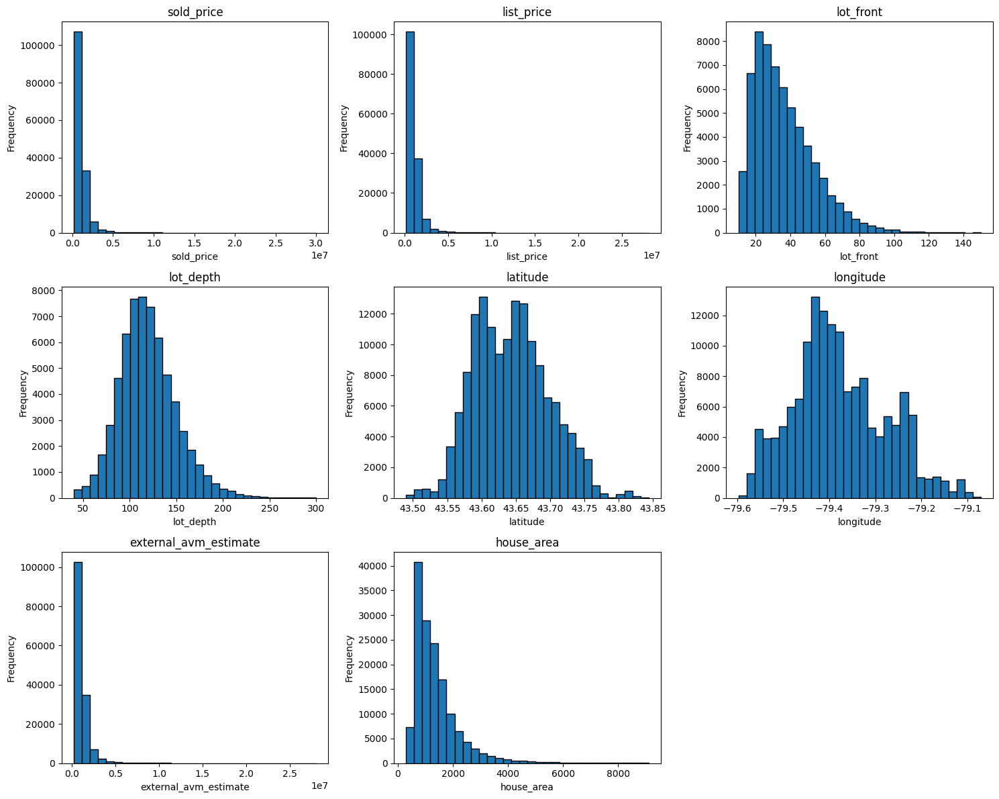

In [9]:
import math

n_cols = 3
n_rows = math.ceil(len(continuous_features) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, feature in enumerate(continuous_features):
    axes[i].hist(listings[feature].dropna(), bins=30, edgecolor="black")
    axes[i].set_title(feature)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Frequency")

# Remove unused subplots
for i in range(len(continuous_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

#### What do these sick ass distributions mean:
- okie everything looks super right skewed, not epic.
- latitude and longitude have a couple of spikes, could look into further.

### Categorical Feature Visualization

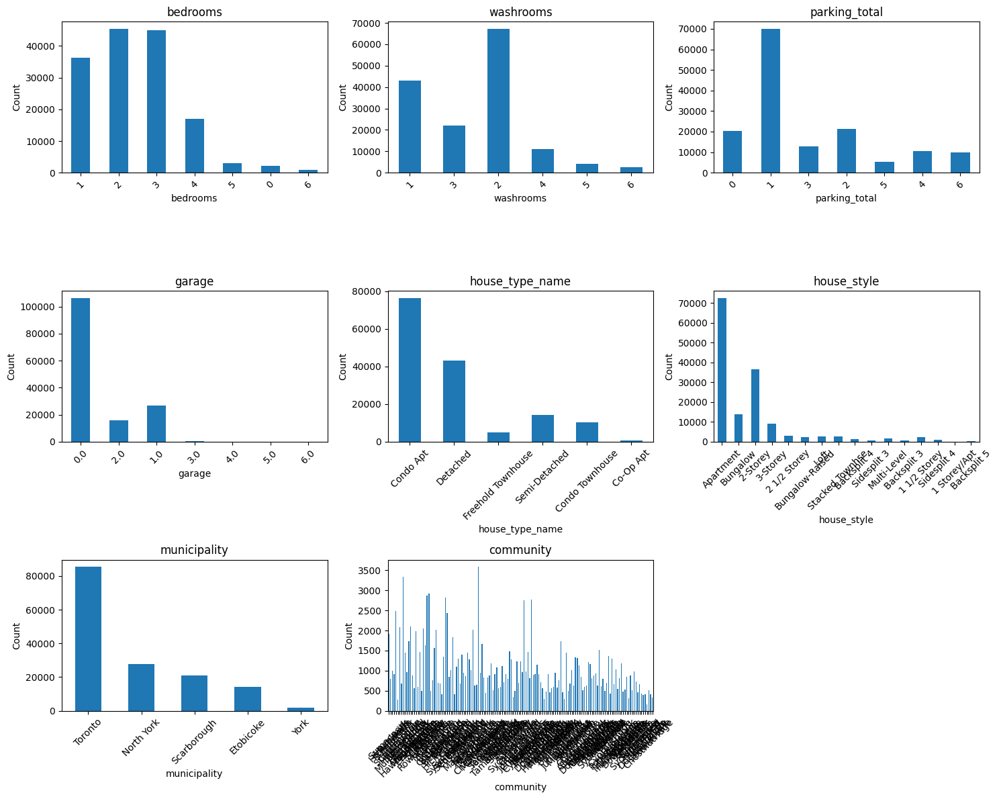

In [10]:
n_cols = 3
n_rows = math.ceil(len(categorical_features) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    listings[feature].value_counts(sort=False).plot(kind="bar", ax=axes[i])
    axes[i].set_title(feature)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=45)

for i in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

### Cool Notes Here

# Relationship between Numeric Features

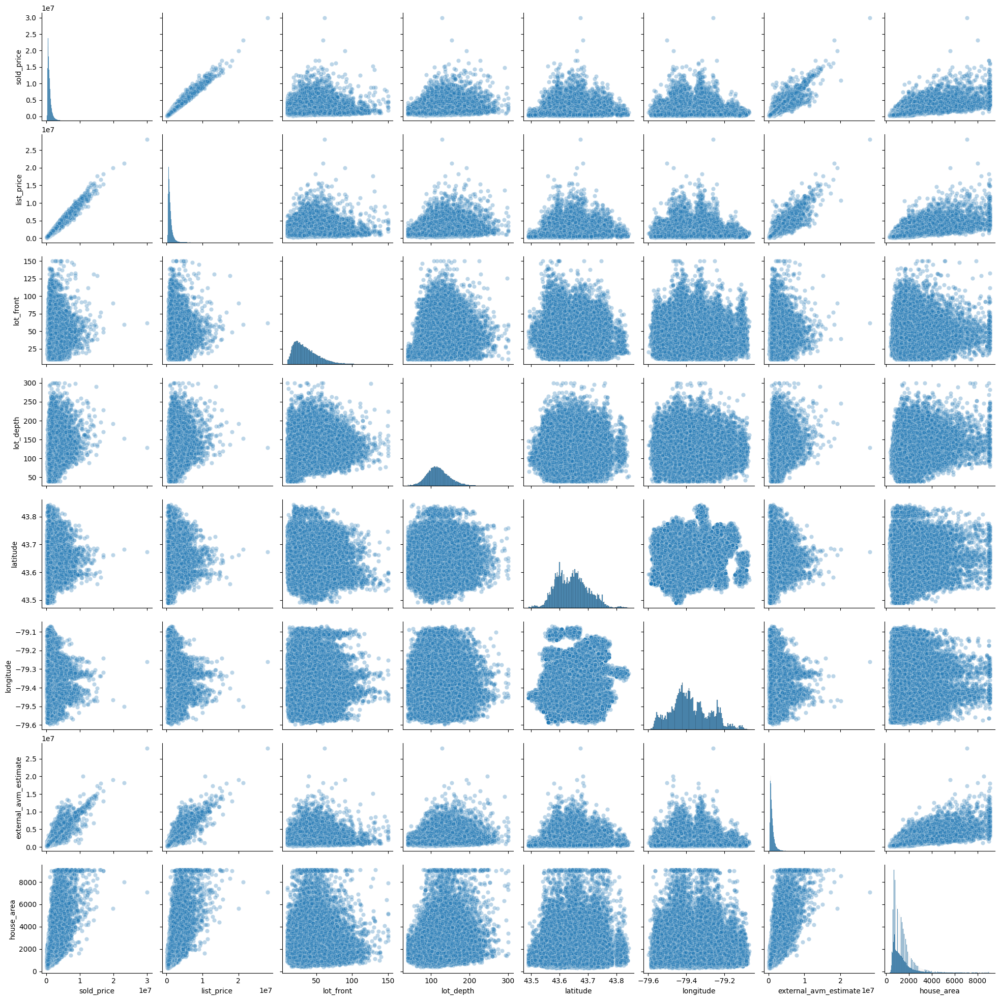

In [11]:
# Scatterplots with regression lines for continuous features
sns.pairplot(
    listings,
    vars=continuous_features,
    plot_kws={"alpha": 0.3},
)

plt.show()

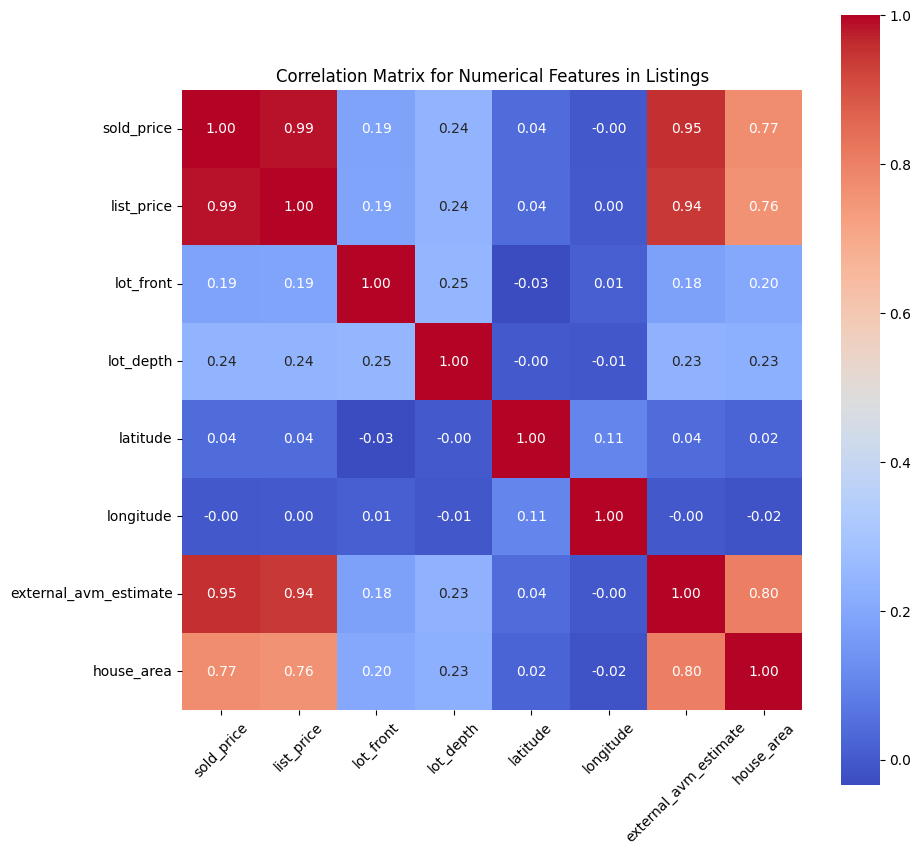

In [12]:
# correlation matrix
corr_matrix = listings[continuous_features].corr()
plt.figure(figsize=(10, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.xticks(rotation=45)
plt.title("Correlation Matrix for Numerical Features in Listings")
plt.show()

# Relationships Between Categorical Features

/tmp/ipykernel_1664262/482377970.py:18: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()





In [13]:
fig, axes = plt.subplots(len(categorical_features) * (len(categorical_features) - 1) // 2, 1,
                         figsize=(10, 5 * (len(categorical_features) * (len(categorical_features) - 1) // 2)))
axes = axes.flatten()
idx = 0

for i in range(len(categorical_features)):
    for j in range(i + 1, len(categorical_features)):
        f1, f2 = categorical_features[i], categorical_features[j]

        pd.crosstab(listings[f1], listings[f2], normalize="index").plot(
            kind="bar", stacked=True, ax=axes[idx]
        )
        axes[idx].set_title(f"Proportion of {f1} and {f2}")
        axes[idx].set_ylabel("Proportion")
        axes[idx].legend(title=f2, bbox_to_anchor=(1.02, 1))
        idx += 1

plt.tight_layout()
plt.show()

# Relationships Between Categorical and Continuous Variables

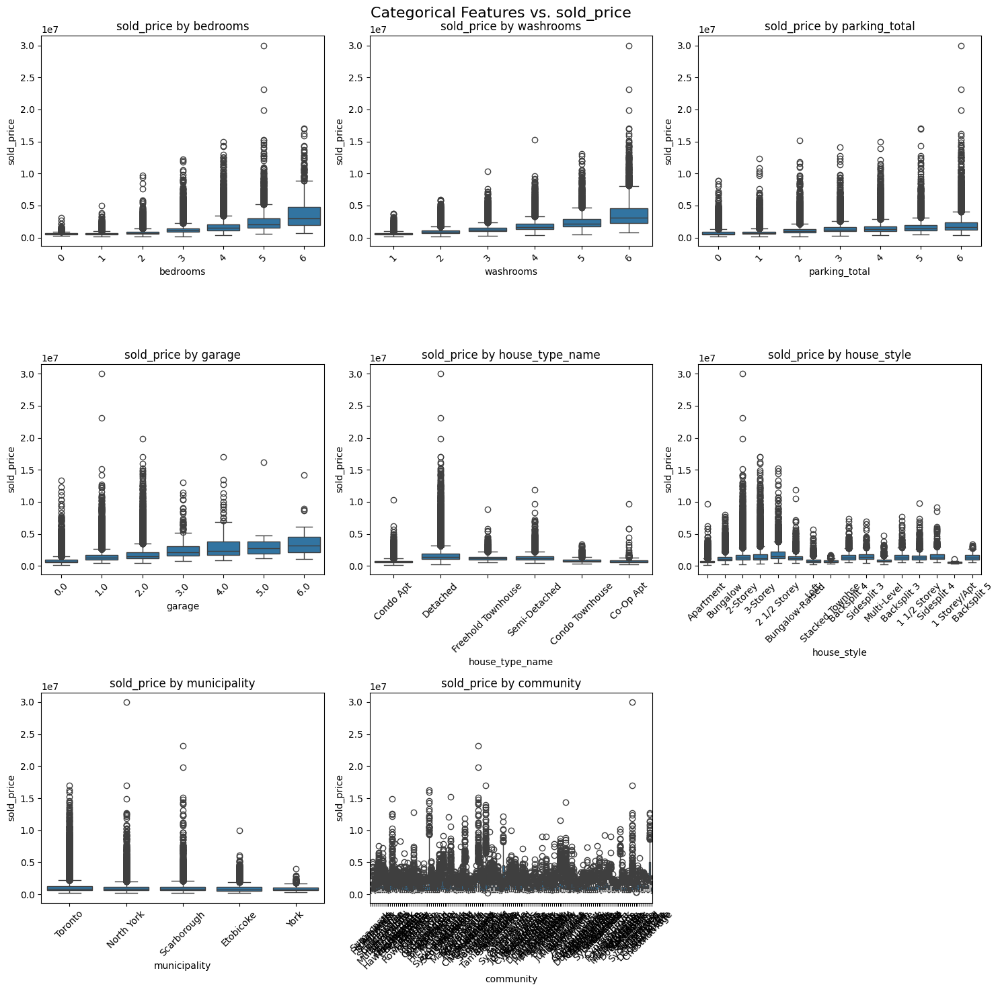

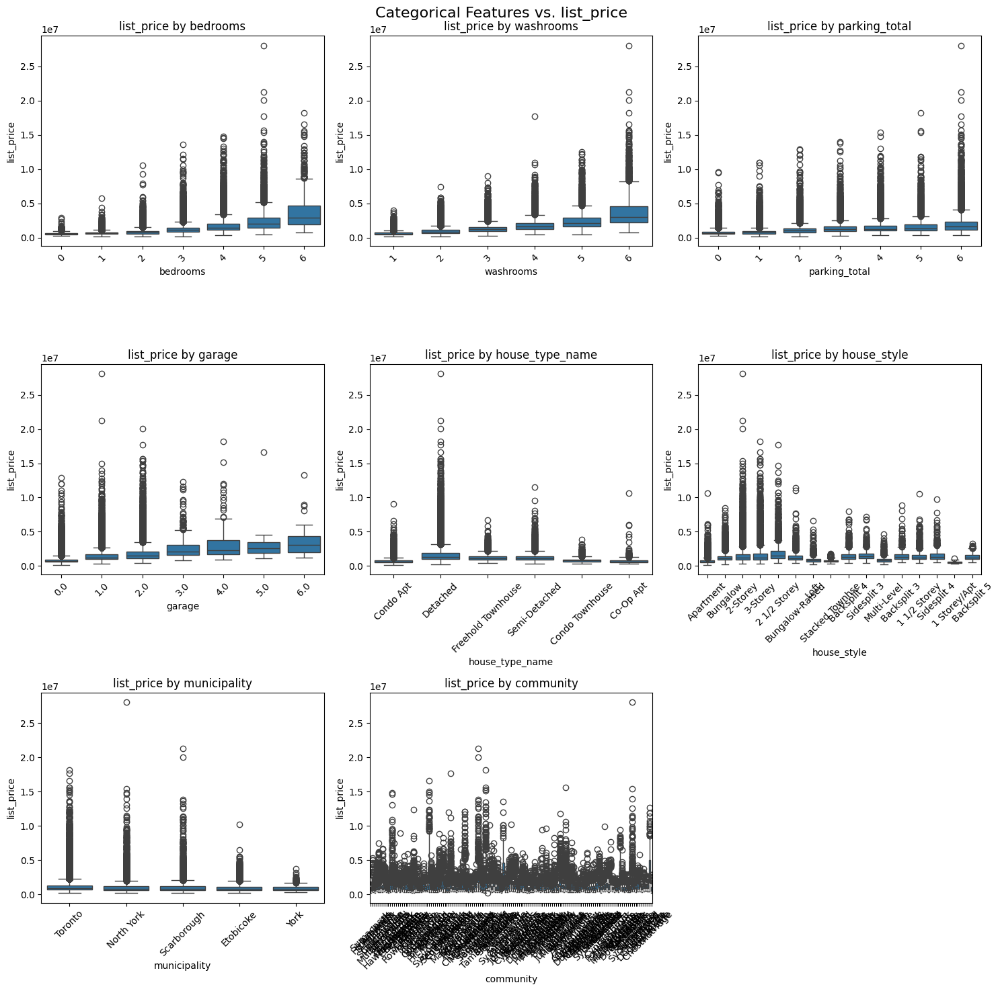

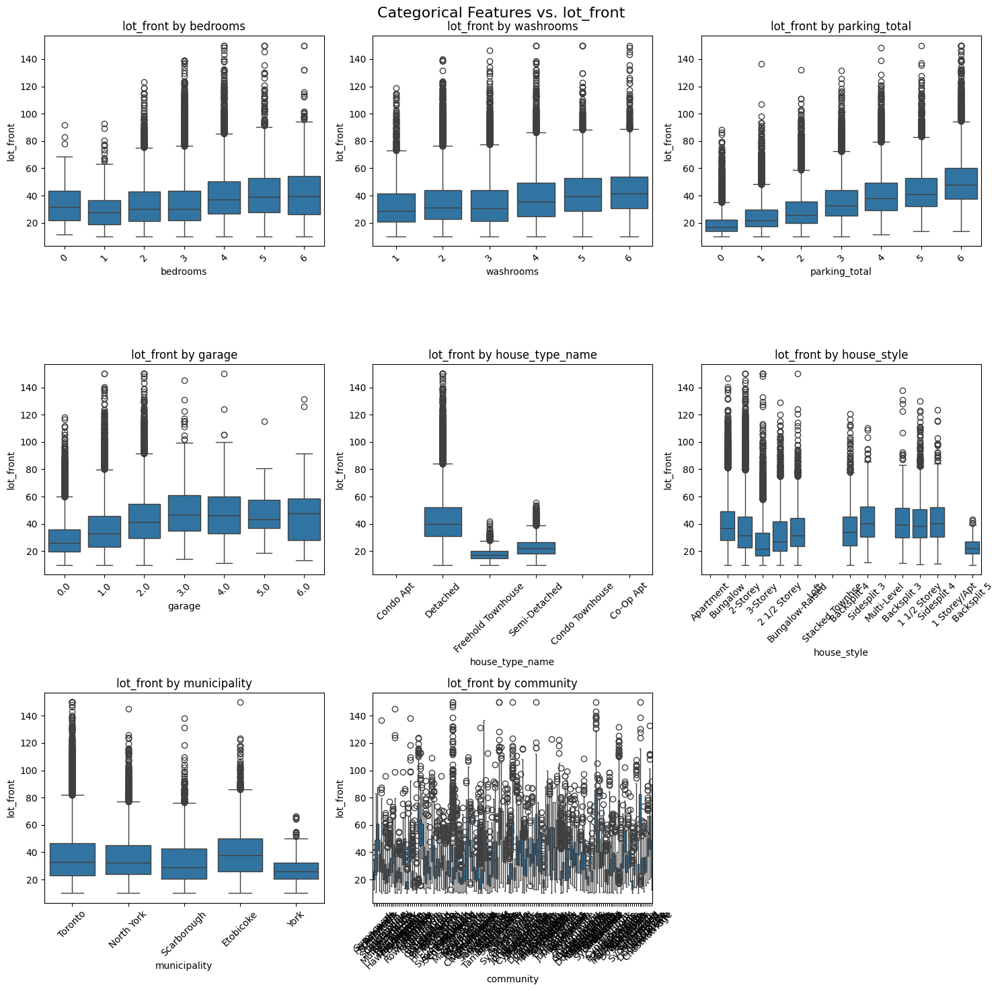

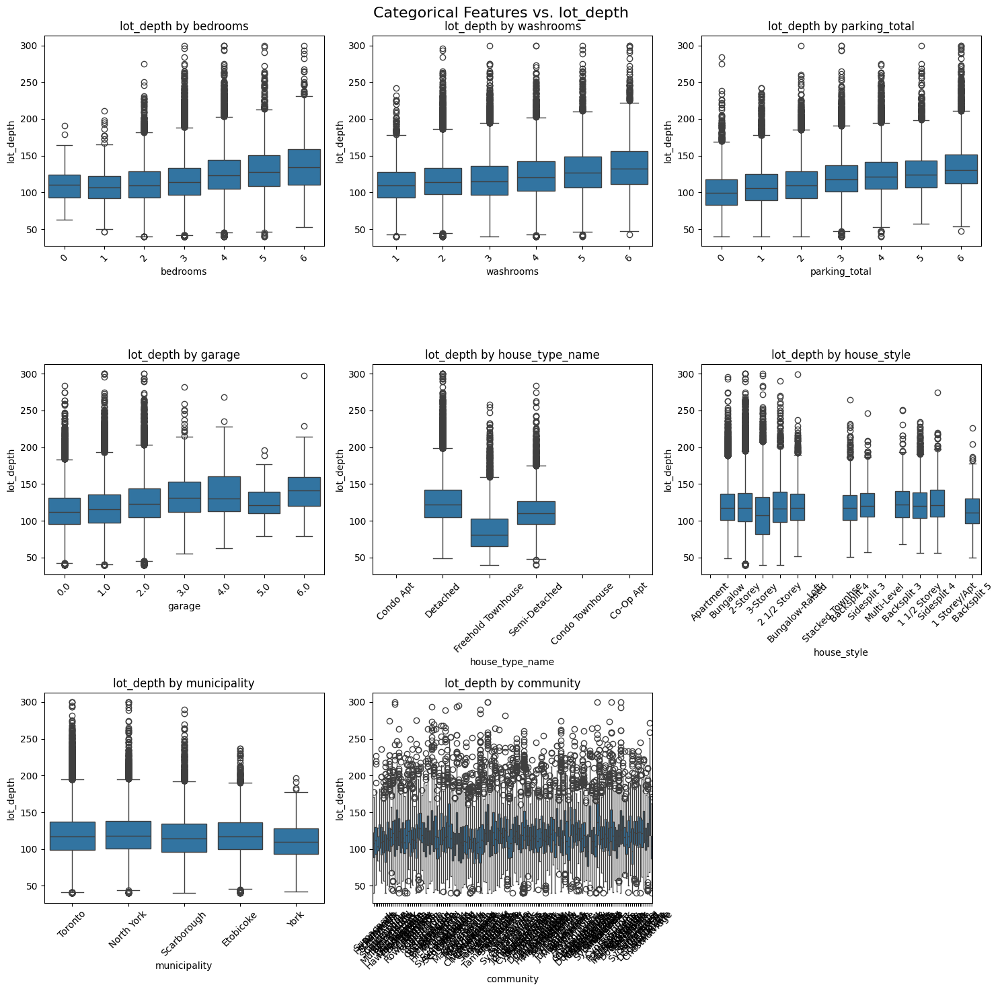

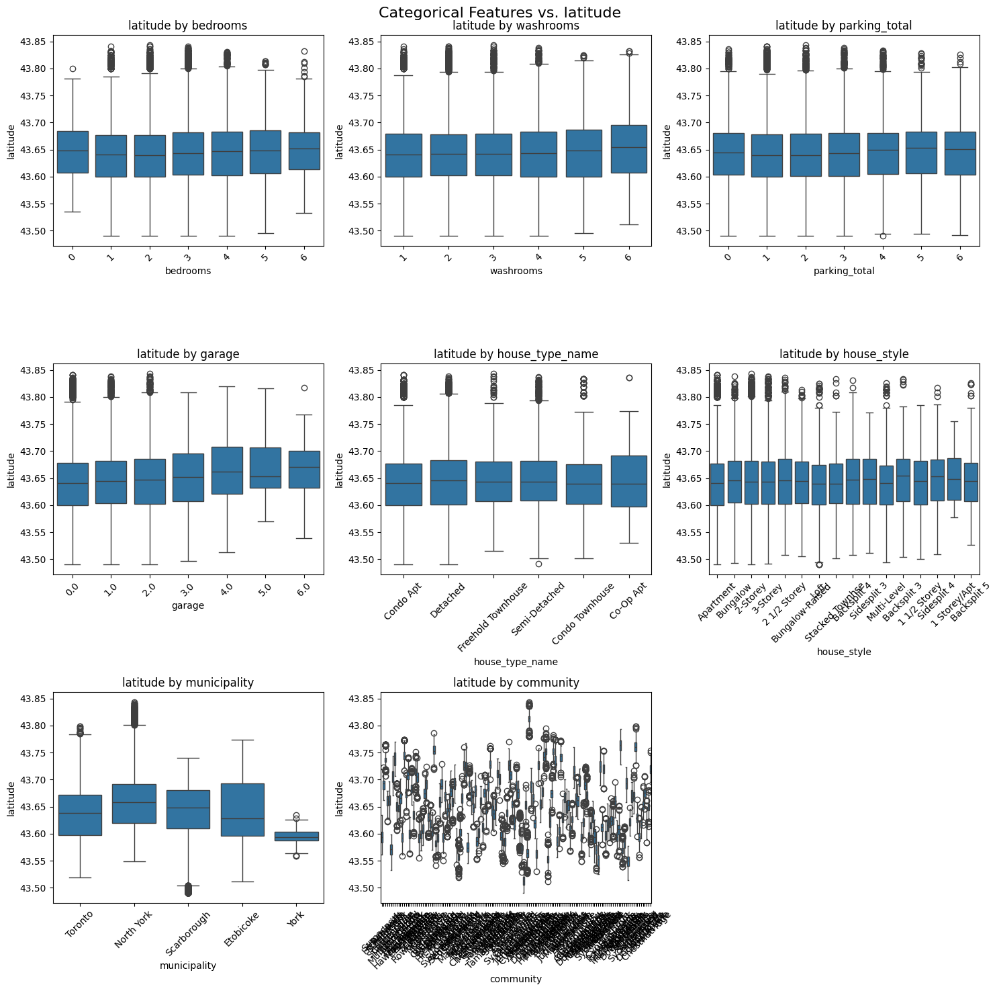

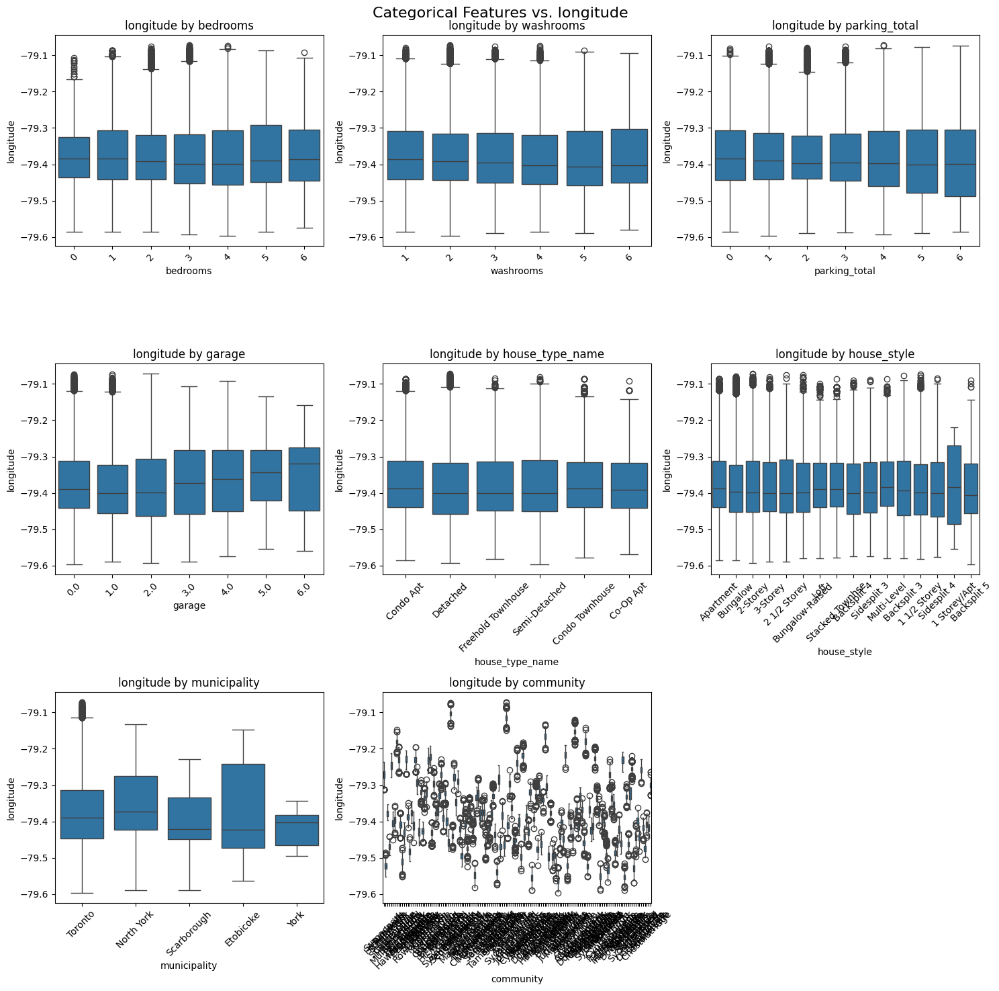

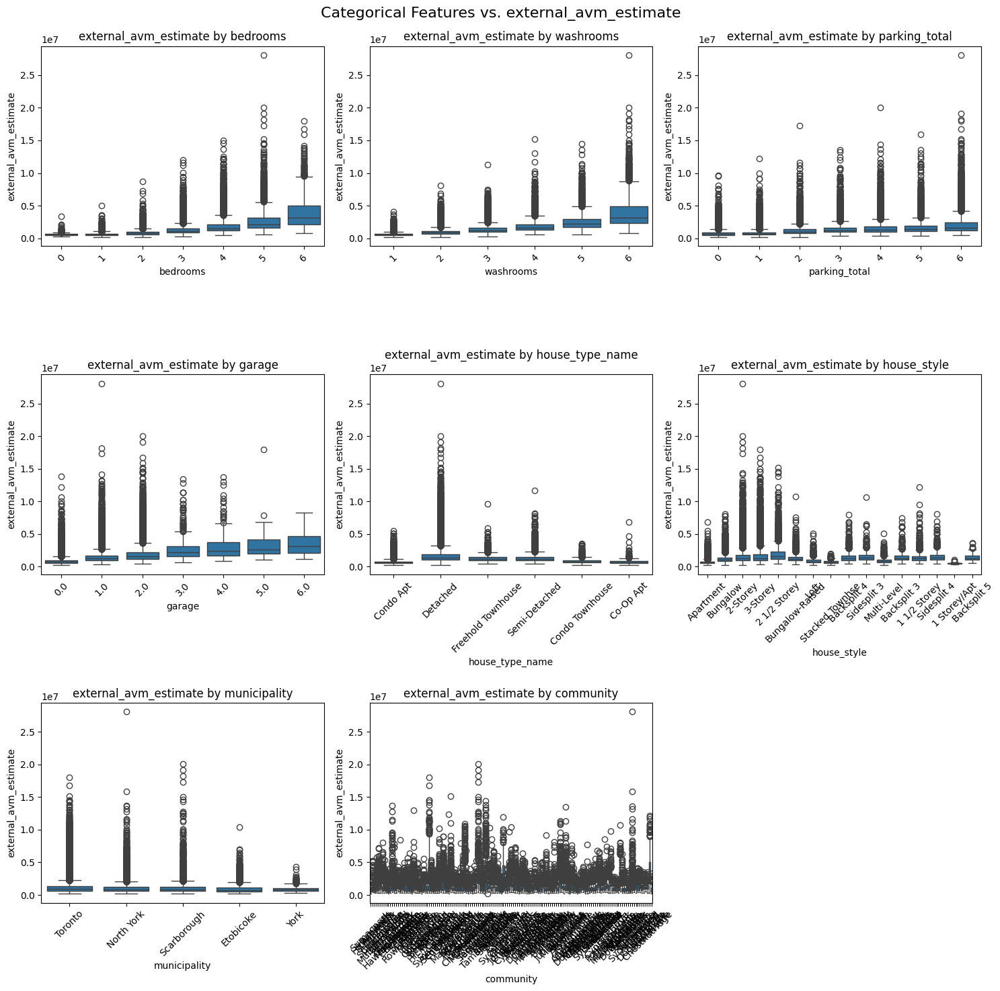

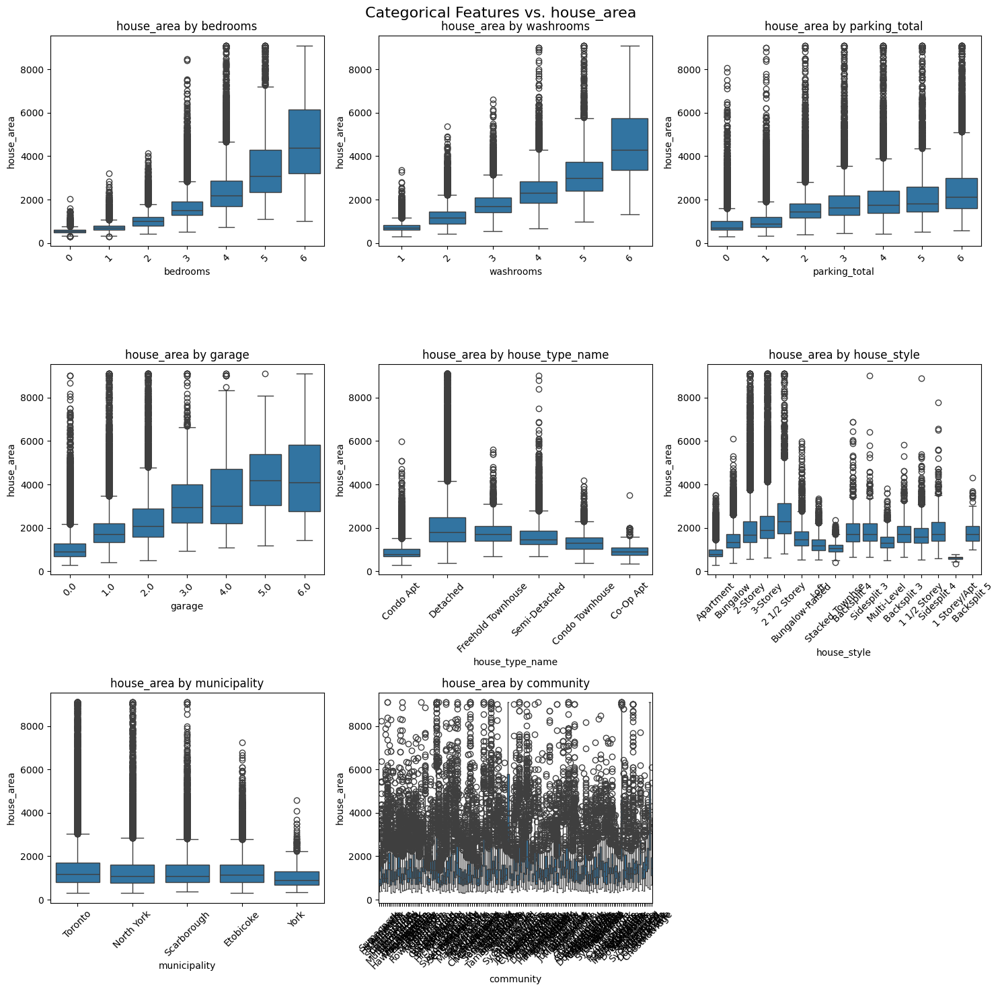

In [14]:
# Box Plots for Everything!
for cont in continuous_features:
    n_cols = 3
    n_rows = math.ceil(len(categorical_features) / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(15, 5 * n_rows)
    )
    axes = axes.flatten()

    for i, categorical_feat in enumerate(categorical_features):
        sns.boxplot(data=listings, x=categorical_feat, y=cont, ax=axes[i])
        axes[i].set_title(f"{cont} by {categorical_feat}")
        axes[i].tick_params(axis="x", rotation=45)

    for i in range(len(categorical_features), len(axes)):
        fig.delaxes(axes[i])

    fig.suptitle(f"Categorical Features vs. {cont}", fontsize=16)
    plt.tight_layout()
    plt.show()

## Time Series Analysis!

In [15]:
listings["month"] = listings["date_listed"].dt.month
listings["year"] = listings["date_listed"].dt.year
listings["day"] = listings["date_listed"].dt.day
listings["days_since_2021"] = (listings["date_listed"] - pd.Timestamp("2021-01-01")).dt.days

time_features = ['month', 'year', 'day', 'days_since_2021']

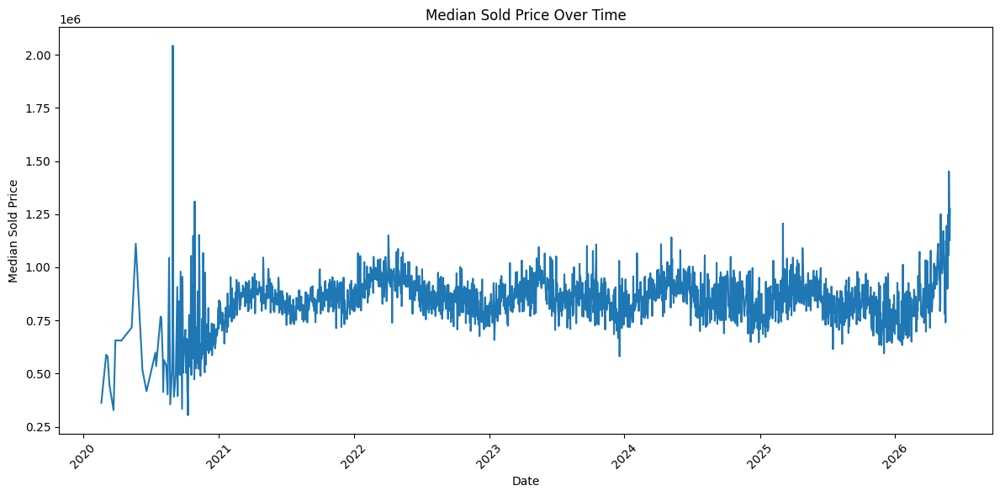

In [16]:
daily_median = listings.groupby(listings["date_listed"])["sold_price"].median()

plt.figure(figsize=(12, 6))
plt.plot(daily_median.index, daily_median.values)
plt.xlabel("Date")
plt.ylabel("Median Sold Price")
plt.title("Median Sold Price Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

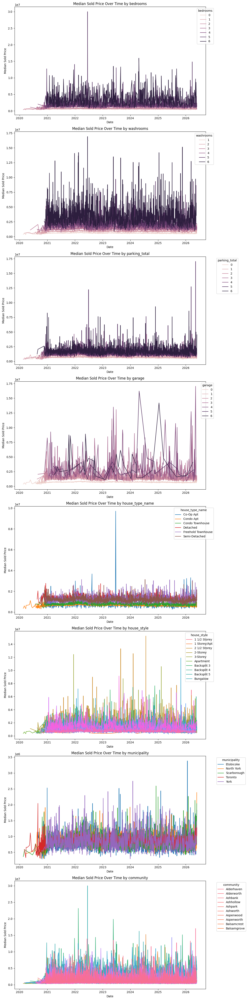

In [17]:
# Sold Price Over Time Grouped By Categorical Features
categorical_features = ['bedrooms', 'washrooms', 'parking_total', 'garage', 'house_type_name', 'house_style', 'municipality', 'community']

fig, axes = plt.subplots(len(categorical_features), 1, figsize=(12, 6 * len(categorical_features)))
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    grouped = listings.groupby([feature, 'date_listed'])['sold_price'].median().reset_index()
    sns.lineplot(data=grouped, x='date_listed', y='sold_price', hue=feature, ax=axes[i])
    axes[i].set_title(f'Median Sold Price Over Time by {feature}')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Median Sold Price')
    handles, labels = axes[i].get_legend_handles_labels()
    axes[i].legend(handles[:10], labels[:10], title=feature, bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()